# Data loading and cleaning

In [2]:
#importing the libraries we need to use for data analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import shap
from sklearn.ensemble import GradientBoostingRegressor

print("All good")

All good


/Users/aleksrzesny/Desktop/LUISS Y1/Python and R/labds/labds/AI-Productivity/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#load the data set into the data frame(allows us to start exploring for potential data cleanups)
df = pd.read_csv("ai_productivity_dataset_final.csv")

# set display.max_columns to None so we can see all of them
pd.set_option('display.max_columns', None)

# first 5 rows to get a gist of what the data looks like
df.head()

,task_id,client,project_id,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,created_by,updated_at,task_status,workflow_stage,jira_ticket,legacy_ai_flag,content_version
0,T00000,Client_F,P038,mid,Content,report,junior,2,3.0,high,0,hourly,2025-11-20,2025-11-25,10.0,0,7.63,5.14,0.75,True,1,1,2.10,69.93,498.11,346.17,151.94,user_096,2025-11-28,review,finalized,JIRA-49014,true,v1
1,T00001,Client_H,P028,low,Paid Media,release,junior,1,2.0,medium,0,fixed,2026-01-24,2026-01-26,7.0,0,9.52,8.22,0.12,False,1,1,4.48,82.79,847.01,343.18,503.83,user_058,2026-01-26,delivered,client_review,JIRA-84793,false,v1
2,T00002,Client_D,P009,low,Design,dev,junior,3,4.0,medium,0,fixed,2025-09-16,2025-09-23,5.0,1,8.45,6.15,0.37,True,2,0,2.71,76.40,1374.07,365.02,1009.05,user_074,2025-09-17,in_progress,qa,JIRA-42485,true,v2
3,T00003,Client_E,P023,mid,Content,design,mid,3,2.0,low,0,hourly,2025-11-06,2025-11-09,3.0,0,28.35,24.22,0.07,False,4,1,0.00,NaN,2379.11,1514.73,864.38,user_011,2025-11-12,in_progress,briefing,JIRA-53111,false,v1
4,T00004,Client_C,P014,low,Design,article,senior,2,5.0,low,0,fixed,2026-05-02,2026-05-06,7.0,0,5.93,4.44,0.20,True,2,2,0.84,NaN,709.95,335.27,374.68,user_007,2026-05-09,review,execution,JIRA-86006,true,v2


In [4]:
# checking the column names to see what variables we are working with
print("Columns:", df.columns)

# getting general information about the dataset to check for missing values
df.info()

#rows and columns
print("Shape:", df.shape)

Columns: Index(['task_id', 'client', 'project_id', 'client_tier', 'team', 'task_type',
       'seniority', 'task_complexity_score', 'brief_quality_score',
       'deadline_pressure', 'scope_change_flag', 'pricing_model', 'created_at',
       'delivered_at', 'sla_days', 'sla_breach', 'hours_spent',
       'billable_hours', 'ai_usage_pct', 'ai_assisted', 'revisions', 'errors',
       'rework_hours', 'outcome_score', 'revenue', 'cost', 'profit',
       'created_by', 'updated_at', 'task_status', 'workflow_stage',
       'jira_ticket', 'legacy_ai_flag', 'content_version'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 3248 entries, 0 to 3247
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   task_id                3248 non-null   str    
 1   client                 3248 non-null   str    
 2   project_id             3248 non-null   str    
 3   client_tier            3248 non-null   str   

In [5]:
#so we don't accidentally change the original dataset
df_clean = df.copy()

In [6]:
#remove columns with no useful information
cols_to_drop = ['task_id', 'client', 'project_id', 'created_by', 'updated_at', 'jira_ticket', 'legacy_ai_flag']
df_clean = df_clean.drop(columns=cols_to_drop)

In [7]:
# check for improperly labeled values
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(), 
      sep='\n\n')

team
Content       803
Media         781
Design        761
SEO           747
seo            29
media          25
content        22
design         19
SEO            18
DESIGN         12
Paid Media      8
Contennt        8
MEDIA           7
Desgn           6
CONTENT         2
Name: count, dtype: int64

client_tier
mid     1514
low      877
high     857
Name: count, dtype: int64

task_type
design            456
ad                453
ticket            451
report            447
article           446
dev               435
release           421
article_task       15
ad_task            11
relese             11
ticket_task        11
design_task        10
Ticket              8
Report              8
release_task        8
report_task         7
Design              7
Ad                  6
development         5
creative            5
dev_task            4
repport             4
paid_ad             4
artcle              3
support_ticket      3
Release             3
blog_article        3
DEV             

In [8]:
# set all string values to lowercase and rename those labeled incorrectly
for col in df_clean.select_dtypes(include=['object', 'string']).columns:
    df_clean[col] = df_clean[col].str.lower()

df_clean['team'] = df_clean['team'].replace({
    'seo ': 'seo',
    'contennt': 'content',
    'desgn': 'design',
    'paid media': 'media'
})

df_clean['task_type'] = df_clean['task_type'].replace({
    'article_task': 'task',
    'ad_task': 'ad',
    'relese': 'release',
    'ticket_task': 'ticket',
    'design_task': 'design',
    'release_task': 'release',
    'report_task': 'report',
    'development': 'dev',
    'creative': 'design',
    'dev_task': 'dev',
    'repport': 'report',
    'paid_ad': 'ad',
    'artcle': 'article',
    'support_ticket': 'ticket',
    'blog_article': 'article'
})

In [9]:
# check value counts again to make sure all values were handled properly
print(df_clean['team'].value_counts(),
      df_clean['client_tier'].value_counts(), 
      df_clean['task_type'].value_counts(),
      df_clean['seniority'].value_counts(),
      df_clean['deadline_pressure'].value_counts(),
      df_clean['pricing_model'].value_counts(),
      df_clean['task_status'].value_counts(),
      df_clean['workflow_stage'].value_counts(),
      sep='\n\n')

team
content    835
media      821
design     798
seo        794
Name: count, dtype: int64

client_tier
mid     1514
low      877
high     857
Name: count, dtype: int64

task_type
design     478
ad         474
ticket     473
report     466
article    453
dev        446
release    443
task        15
Name: count, dtype: int64

seniority
mid       1296
junior    1190
senior     762
Name: count, dtype: int64

deadline_pressure
medium    1482
low        914
high       852
Name: count, dtype: int64

pricing_model
hourly         1561
fixed          1227
value_based     460
Name: count, dtype: int64

task_status
in_progress    1129
review          866
delivered       769
draft           183
archived        151
blocked         150
Name: count, dtype: int64

workflow_stage
qa               687
client_review    664
finalized        643
briefing         640
execution        614
Name: count, dtype: int64


In [10]:
# drop 15 tasks labeled as "task"
df_clean = df_clean[df_clean['task_type'] != 'task']

In [11]:
#summary of all columns(numerical & categorical);to understand general patterns in the dataa
df_clean.describe(include='all')

,client_tier,team,task_type,seniority,task_complexity_score,brief_quality_score,deadline_pressure,scope_change_flag,pricing_model,created_at,delivered_at,sla_days,sla_breach,hours_spent,billable_hours,ai_usage_pct,ai_assisted,revisions,errors,rework_hours,outcome_score,revenue,cost,profit,task_status,workflow_stage,content_version
count,3233,3233,3233,3233,3233.000000,3164.000000,3233,3233.000000,3233,3233,3196,3197.000000,3233.000000,3233.000000,3151.000000,3089.000000,3233,3233.000000,3233.000000,3162.000000,3100.000000,3233.000000,3233.000000,3233.000000,3233,3233,3233
unique,3,4,7,3,NaN,NaN,3,NaN,3,330,335,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6,5,5
top,mid,content,design,mid,NaN,NaN,medium,NaN,hourly,2026-03-27,2026-01-18,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,in_progress,qa,v1
freq,1506,830,478,1294,NaN,NaN,1475,NaN,1555,22,19,NaN,NaN,NaN,NaN,NaN,2548,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1125,682,920
mean,NaN,NaN,NaN,NaN,2.869780,3.181732,NaN,0.137952,NaN,NaN,NaN,5.018142,0.397773,13.055105,8.439149,0.361379,NaN,3.005258,1.014847,2.433680,68.838981,1121.564536,772.210829,349.353707,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,1.196139,1.210987,NaN,0.344903,NaN,NaN,NaN,2.521184,0.489514,11.544270,4.789097,0.199398,NaN,1.803712,1.042311,2.911877,12.624994,843.028776,585.359090,889.807709,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,0.000000,NaN,NaN,NaN,2.000000,0.000000,0.020000,-1.900000,0.000000,NaN,0.000000,0.000000,0.000000,9.000000,45.000000,77.850000,-8510.549511,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,2.000000,2.000000,NaN,0.000000,NaN,NaN,NaN,3.000000,0.000000,7.930000,5.085000,0.200000,NaN,2.000000,0.000000,1.110000,60.867500,647.030000,440.460000,-2.860000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,3.000000,3.000000,NaN,0.000000,NaN,NaN,NaN,5.000000,0.000000,11.120000,7.540000,0.340000,NaN,3.000000,1.000000,1.810000,69.350000,967.570000,649.210000,254.820000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,4.000000,4.000000,NaN,0.000000,NaN,NaN,NaN,7.000000,1.000000,15.360000,10.695000,0.500000,NaN,4.000000,2.000000,2.940000,77.542500,1364.600000,943.850000,590.580000,NaN,NaN,NaN


# Missing values

Because brief_quality_score, sla_days, billable_hours, ai_usage_pct, rework_hours, and outcome_score are all numeric features we can easily impute them using iterative imputation. We can assume missing values depend on multiple features, therefore this approach is justifiable. Unfortunately, delivered_at can't be imputed, thus these rows will be removed.

(Code used as in the tutorials)


client_tier                0
team                       0
task_type                  0
seniority                  0
task_complexity_score      0
brief_quality_score       69
deadline_pressure          0
scope_change_flag          0
pricing_model              0
created_at                 0
delivered_at              37
sla_days                  36
sla_breach                 0
hours_spent                0
billable_hours            82
ai_usage_pct             144
ai_assisted                0
revisions                  0
errors                     0
rework_hours              71
outcome_score            133
revenue                    0
cost                       0
profit                     0
task_status                0
workflow_stage             0
content_version            0
dtype: int64


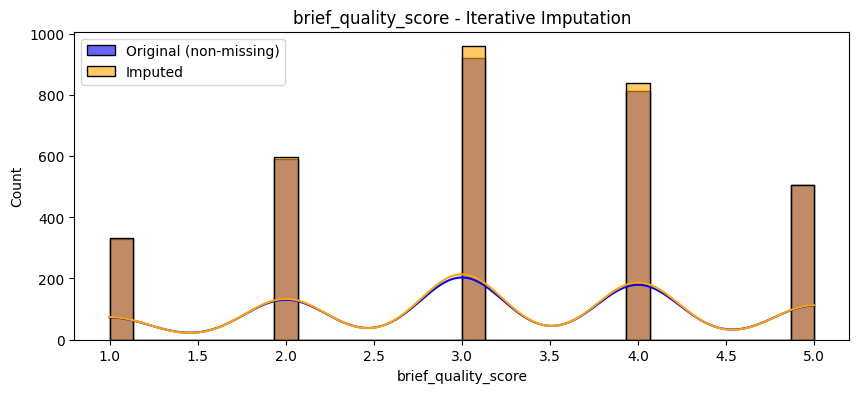

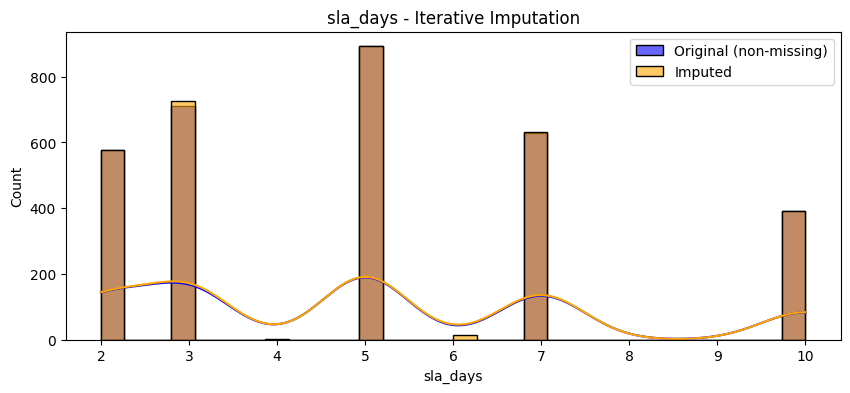

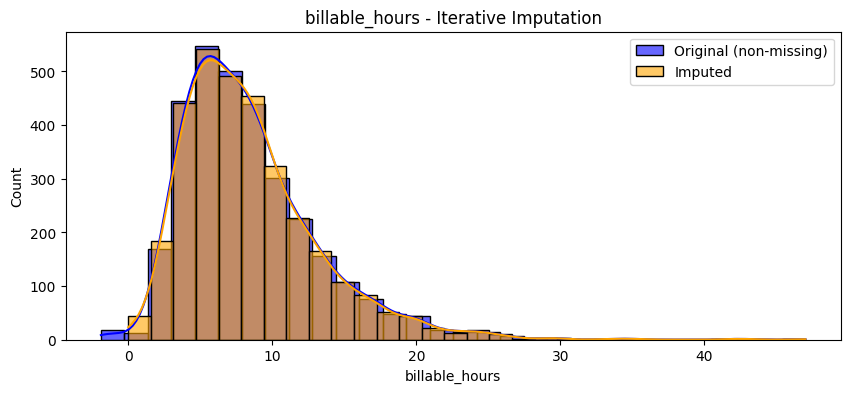

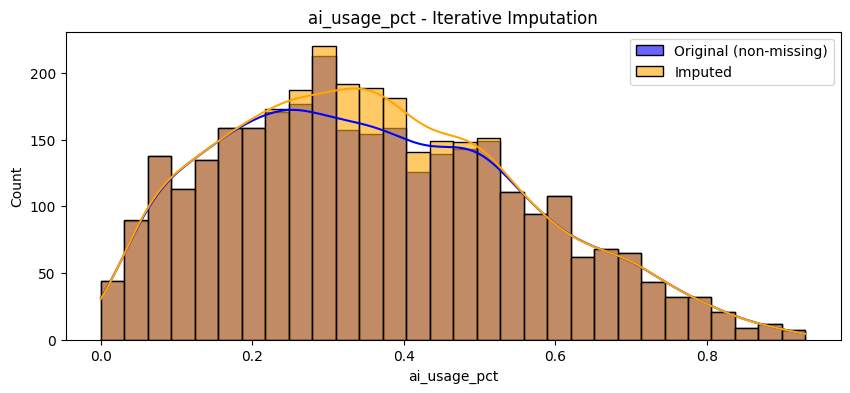

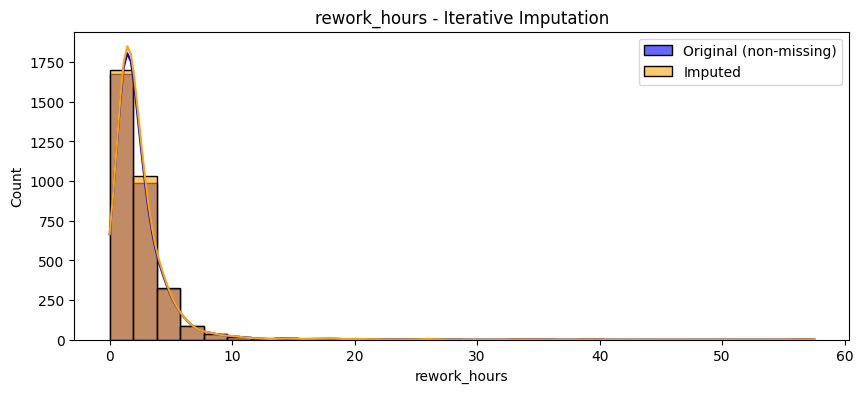

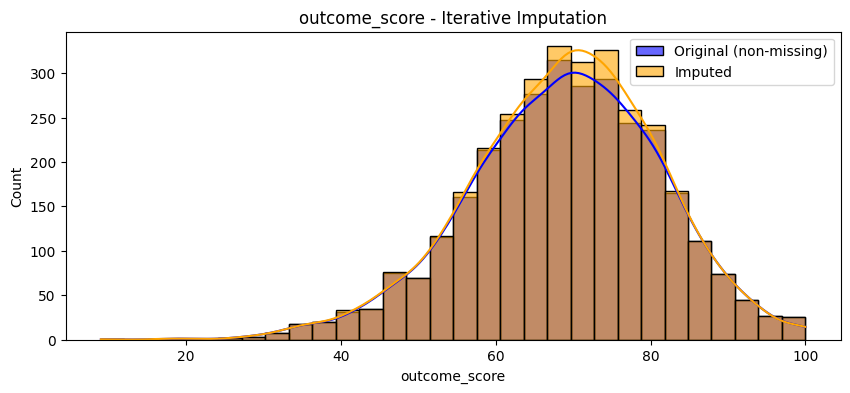

In [12]:
print(df_clean.isnull().sum())

# iterative imputation
df_numerical = df_clean.select_dtypes(include=['number'])

iter_imp = IterativeImputer(random_state=42)
df_iter = pd.DataFrame(iter_imp.fit_transform(df_numerical), columns=df_numerical.columns)

# round brief_quality_score and sla_days such that they are integers
df_iter['brief_quality_score'] = df_iter['brief_quality_score'].round()
df_iter['sla_days'] = df_iter['sla_days'].round()

# remove negative billable_hours
df_iter['billable_hours'] = df_iter['billable_hours'].clip(lower=0)

# plot the orignal vs. imputed distributions of numerical features
def plot_imputation_comparison(original, imputed, title):
    plt.figure(figsize=(10, 4))
    sns.histplot(original.dropna(), kde=True, color='blue', label='Original (non-missing)', bins=30, alpha=0.6)
    sns.histplot(imputed, kde=True, color='orange', label='Imputed', bins=30, alpha=0.6)
    plt.title(title)
    plt.legend()
    plt.show()

for col in df_numerical.columns:
    if df_numerical[col].isnull().any():
        plot_imputation_comparison(df_numerical[col], df_iter[col], f"{col} - Iterative Imputation")

# merge the imputed data back into the original df
df_clean[df_numerical.columns] = df_iter

# drop rows with missing delivered_at values
df_clean = df_clean.dropna()

In [13]:
#checking final shape after cleaning
print("Final shape:", df_clean.shape)
#make sure there arnet missing values left
print(df_clean.isnull().sum())
#confirm no remaining duplicate rows
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Final shape: (3181, 27)
client_tier              0
team                     0
task_type                0
seniority                0
task_complexity_score    0
brief_quality_score      0
deadline_pressure        0
scope_change_flag        0
pricing_model            0
created_at               0
delivered_at             0
sla_days                 0
sla_breach               0
hours_spent              0
billable_hours           0
ai_usage_pct             0
ai_assisted              0
revisions                0
errors                   0
rework_hours             0
outcome_score            0
revenue                  0
cost                     0
profit                   0
task_status              0
workflow_stage           0
content_version          0
dtype: int64
Duplicate rows after cleaning: 0


# EDA


## Heatmap

The heatmap reveals interesting relationships: negative relationship between ai_usage_pct and sla_breach, billable_hours, and cost.

Other interesting relationships include: negative correlations between outcome_score and task_complexity_score, revisions, errors and rework_hours.

No strong trends emerge regarding revenue, cost or profit.


<Axes: >

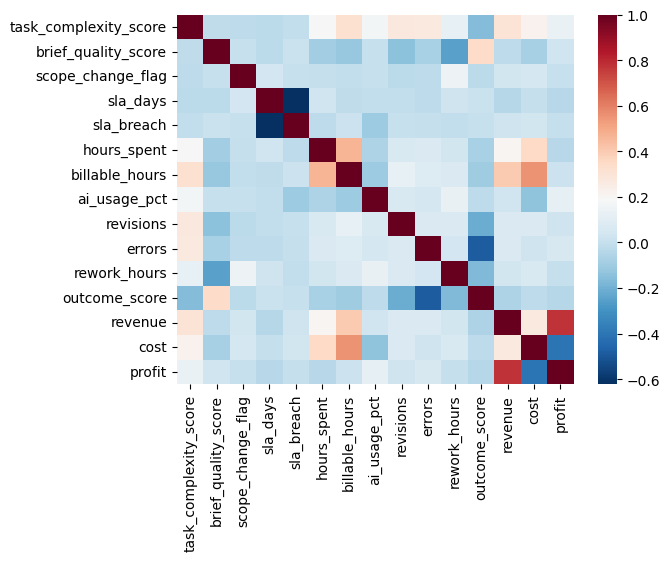

In [14]:
corr = df_numerical.corr()

sns.heatmap(corr, cmap = 'RdBu_r')

## Regression
Preliminary EDA doesn't reveal any striking patterns or trends with respect to (non-)AI-assisted tasks, however helps illustrate the broader picture.

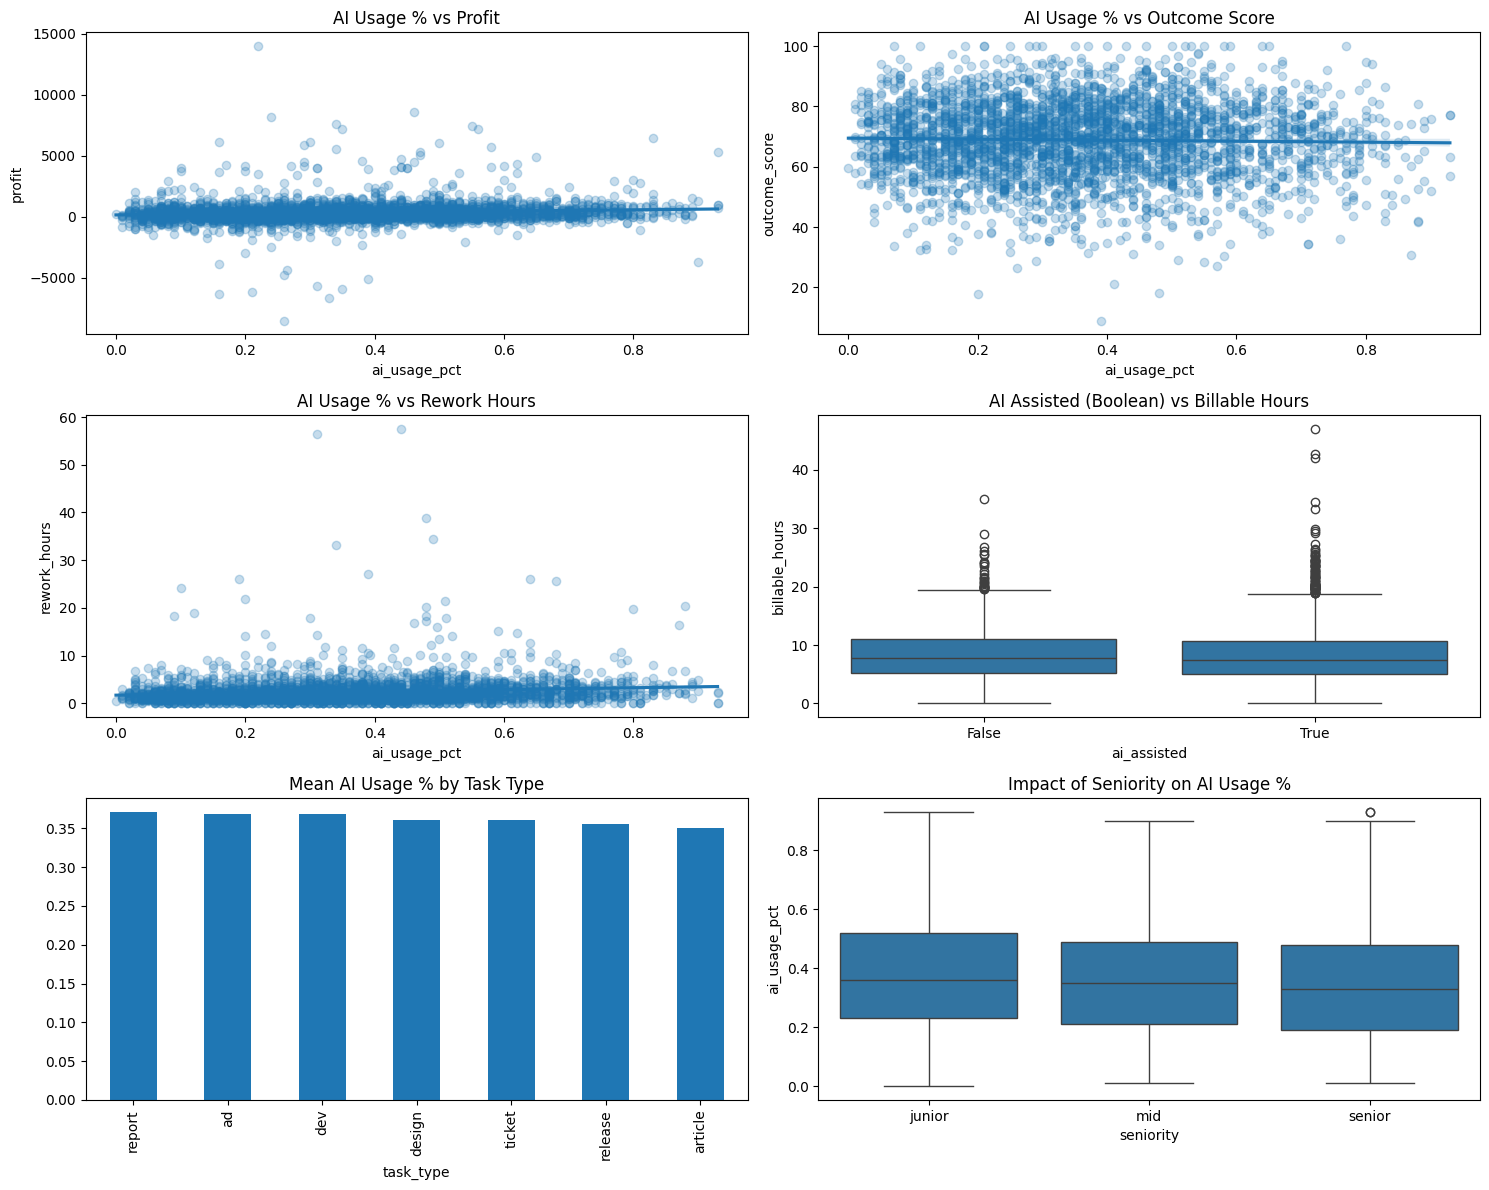

In [15]:
plt.figure(figsize=(15, 12))

plt.subplot(3, 2, 1)
sns.regplot(data=df_clean, x='ai_usage_pct', y='profit', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Profit')

plt.subplot(3, 2, 2)
sns.regplot(data=df_clean, x='ai_usage_pct', y='outcome_score', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Outcome Score')

plt.subplot(3, 2, 3)
sns.regplot(data=df_clean, x='ai_usage_pct', y='rework_hours', scatter_kws={'alpha':0.25})
plt.title('AI Usage % vs Rework Hours')

plt.subplot(3, 2, 4)
sns.boxplot(data=df_clean, x='ai_assisted', y='billable_hours')
plt.title('AI Assisted (Boolean) vs Billable Hours')

plt.subplot(3, 2, 5)
df_clean.groupby('task_type')['ai_usage_pct'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Mean AI Usage % by Task Type')

plt.subplot(3, 2, 6)
sns.boxplot(data=df_clean, x='seniority', y='ai_usage_pct', order=['junior', 'mid', 'senior'])
plt.title('Impact of Seniority on AI Usage %')

plt.tight_layout()

## Gradient Boosting + SHAP values
We use Gradient Boosting and SHAP values to find main influencers for key metrics such as Profit, Outcome Score, Errors, and Hours Spent, as well as how they influence them.

When confounding features are removed, AI use consistently shows up within the top 4 most influential factors for all of the identified metrics, proving its significant impact on value creation.

### Profit
AI Usage % is identified as the 2nd most influential factor of Profit (excluding factors such as profit, revenue, cost, hours spent, and billable hours). Higher AI usage visibly contributes toward greater profits, while low AI usage toward negatively toward profits.

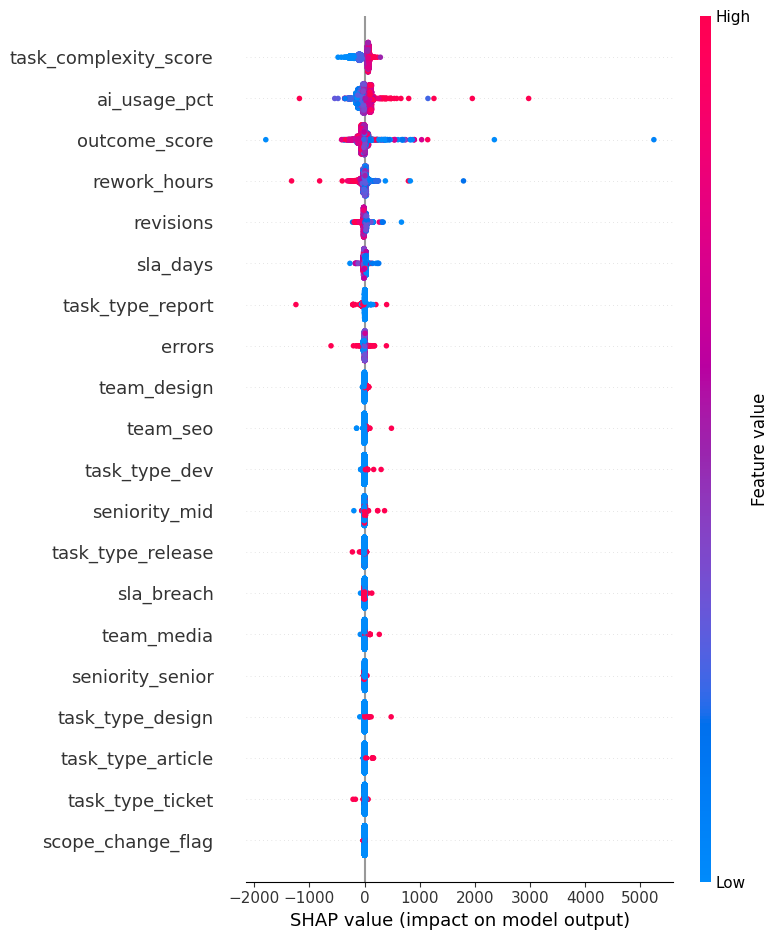

In [16]:
# Main Influencers of Profit

# Merge and align data
X_combined = pd.concat([df_iter.reset_index(drop=True), 
                        df_clean[['team', 'task_type', 'seniority']].reset_index(drop=True)], 
                       axis=1)

# Define target and drop problematic features
y = X_combined['profit']
X = X_combined.drop(columns=['profit', 'revenue', 'hours_spent', 'billable_hours','cost', 'brief_quality_score'])

# Get dummies for categorical features
X = pd.get_dummies(X, drop_first=True)

# Convert booleans to ints and drop any remaining objects (like dates/IDs)
for col in X.columns:
    if X[col].dtype == 'bool':
        X[col] = X[col].astype(int)

# Drop any column that is still not a number
X = X.select_dtypes(include=['number'])

# Train and SHAP
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)

explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_train)

shap.summary_plot(shap_values, X_train)

### Outcome Score
AI Usage % is identified as the 4th most influential factor of Outcome Score (excluding factors such as profit, revenue, cost, and brief quality score). While the story here is not as clear as before, higher AI usage seems to be associated with higher outcome scores on average, however some very negative outliers exist.

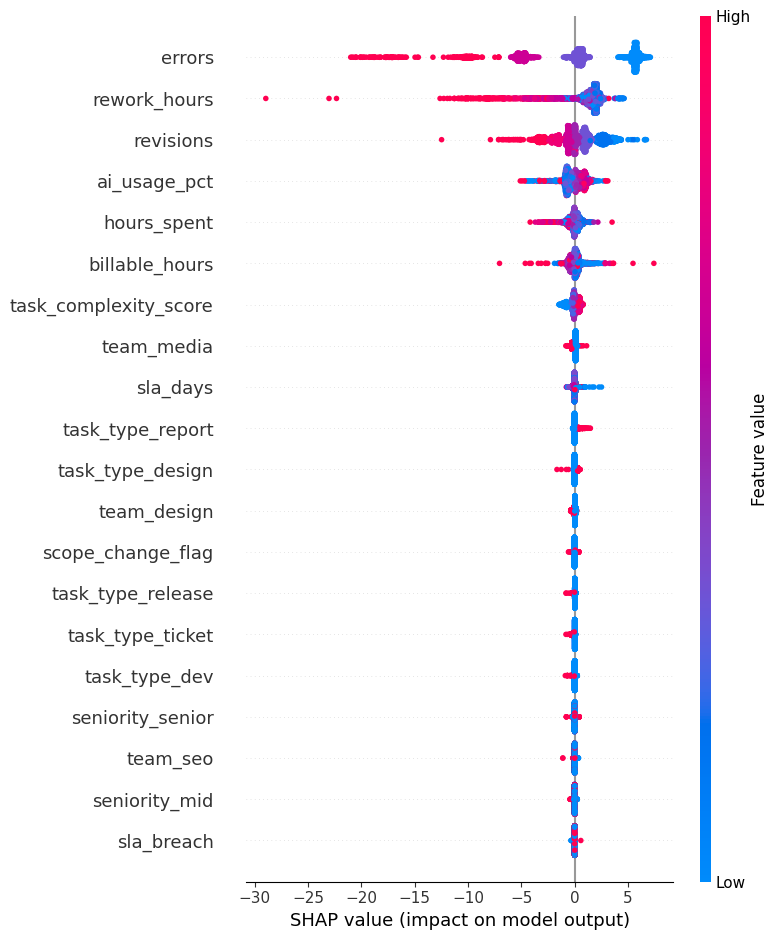

In [17]:
# same process as before, but to find main influences of Outcome Score
y = X_combined['outcome_score']
X = X_combined.drop(columns=['outcome_score', 'profit', 'revenue', 'cost', 'brief_quality_score'])

X = pd.get_dummies(X, drop_first=True)

for col in X.columns:
    if X[col].dtype == 'bool':
        X[col] = X[col].astype(int)

X = X.select_dtypes(include=['number'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)

explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_train)

shap.summary_plot(shap_values, X_train)

### Errors
AI Usage % is identified as the 4th most influential factor of Errors (excluding factors such as profit, revenue, cost, brief quality score, and outcome score). Here high AI usage points toward more errors and low AI usage vice versa.

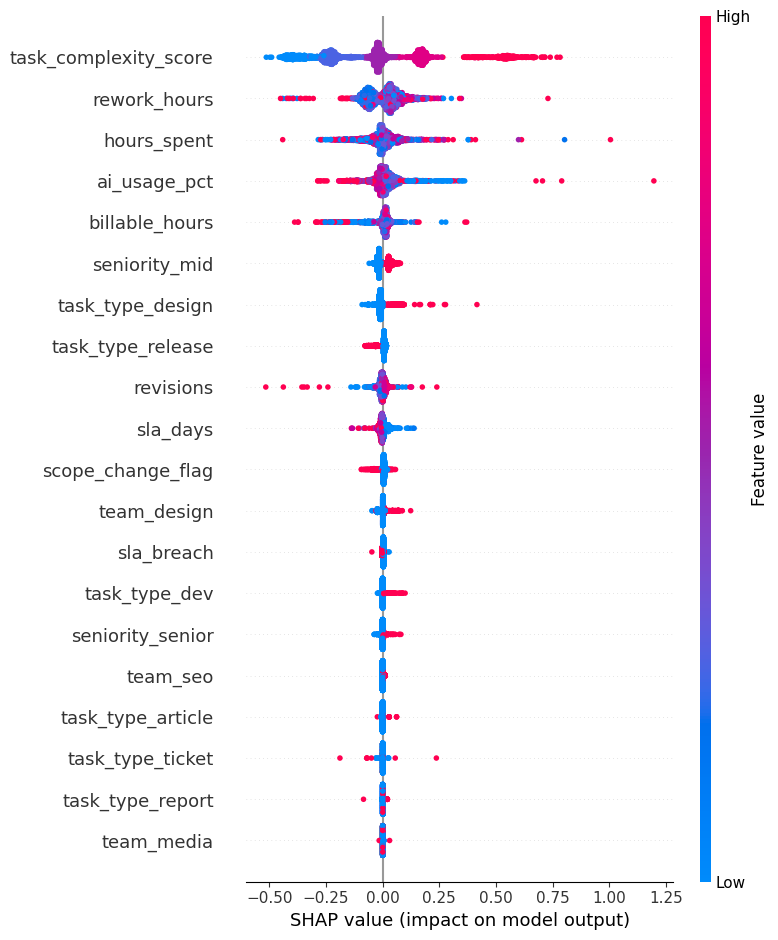

In [18]:
# same process as before, but to find main influences of Errors
y = X_combined['errors']
X = X_combined.drop(columns=['errors', 'outcome_score', 'profit', 'revenue', 'cost', 'brief_quality_score'])

X = pd.get_dummies(X, drop_first=True)

for col in X.columns:
    if X[col].dtype == 'bool':
        X[col] = X[col].astype(int)

X = X.select_dtypes(include=['number'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)

explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_train)

shap.summary_plot(shap_values, X_train)

### Hours Spent
AI Usage % is identified as the 2nd most influential factor of Hours Spent (excluding factors such as profit, revenue, cost, brief quality score, outcome score, and billable hours). High AI usage values reduce hours spent, while low AI usage increases them.

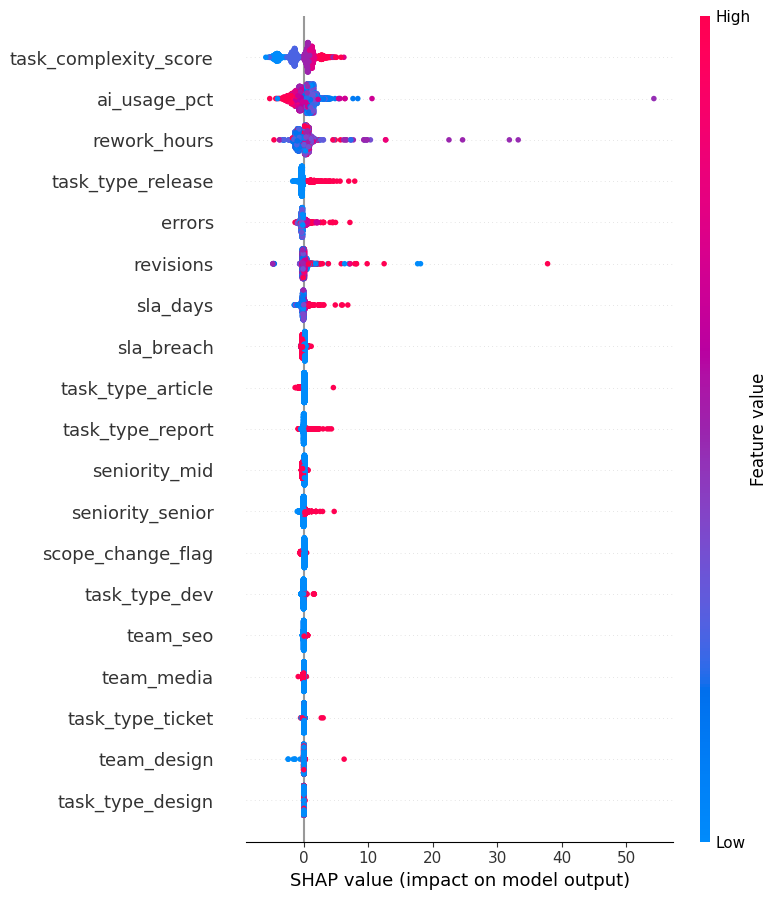

In [19]:
# same process as before, but to find main influencers of Hours Spent
y = X_combined['hours_spent']
X = X_combined.drop(columns=['hours_spent', 'billable_hours', 'outcome_score', 'profit', 'revenue', 'cost', 'brief_quality_score'])

X = pd.get_dummies(X, drop_first=True)

for col in X.columns:
    if X[col].dtype == 'bool':
        X[col] = X[col].astype(int)

X = X.select_dtypes(include=['number'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = GradientBoostingRegressor(random_state=42).fit(X_train, y_train)

explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_train)

shap.summary_plot(shap_values, X_train)

# Analysis


### 1. Where is value created?

Identify tasks where AI produces a measurable and positive impact.

Compare key value drivers such as profit, outcome score and hours spent for tasks accomplished with the use of AI as opposed to without, divided by task type.  This will help us create a clear, normalized comparison which tasks gain value due to the addition of AI and which don't.

In [20]:
# summary table comparing the mean of efficiency metrics given AI vs Non-AI per task
metrics = ['profit', 'outcome_score', 'hours_spent']
impact_df = df_clean.groupby(['task_type', 'ai_assisted'])[metrics].mean().unstack()

# individual lift % for each metric
impact_df['profit_lift'] = (impact_df['profit'][True] - impact_df['profit'][False]) / impact_df['profit'][False]
impact_df['quality_lift'] = (impact_df['outcome_score'][True] - impact_df['outcome_score'][False]) / impact_df['outcome_score'][False]
impact_df['time_savings'] = (impact_df['hours_spent'][False] - impact_df['hours_spent'][True]) / df_clean['hours_spent'].mean()

print(impact_df[['profit_lift', 'quality_lift', 'time_savings']])

            profit_lift quality_lift time_savings
ai_assisted                                      
task_type                                        
ad            -0.432993    -0.014357     0.008633
article        0.098444    -0.004953    -0.067125
design         0.303485     0.008172     0.132090
dev           -0.129568    -0.014363     0.000717
release       -0.141557     0.033882     0.228605
report         0.110661    -0.020783    -0.097337
ticket        -0.255024    -0.000878     0.025254


Next we visualize the results in a bar graph. We can see the tasks that most benefit from AI are release and design tasks.

Text(0, 0.5, 'Normalized Value Score')

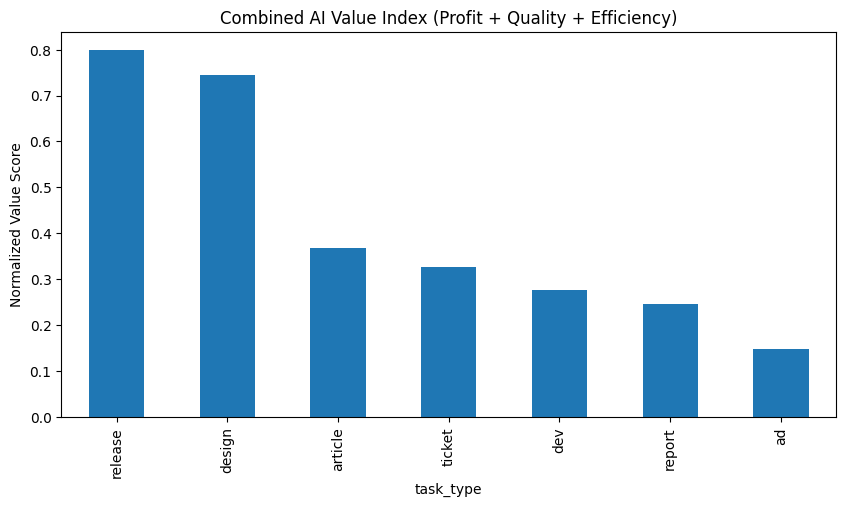

In [21]:
lift_cols = ['profit_lift', 'quality_lift', 'time_savings']
lifts = impact_df[lift_cols]

# normalize all lifts to a 0-1 scale so they carry equal weight
scaler = MinMaxScaler()
normalized_lifts = pd.DataFrame(
    scaler.fit_transform(lifts), 
    index=lifts.index, 
    columns=lift_cols
)

# combined (mean) AI value score
impact_df['AI_Value_Index'] = normalized_lifts.mean(axis=1)

impact_df['AI_Value_Index'].sort_values(ascending=False).plot(kind='bar', figsize=(10,5))
plt.title('Combined AI Value Index (Profit + Quality + Efficiency)')
plt.ylabel('Normalized Value Score')

### 2. Where are losses incurred?

Track losses: rework, declining quality, hidden costs


We now do the opposite – instead of creating a value index, we create a loss index, tracking rework hours, extra hours and outcome score. 

In [22]:
#hidden cost = hours spent but not billed
df_clean['extra_hours'] = df_clean['hours_spent'] - df_clean['billable_hours']

In [23]:
#summary table comparing mean loss metrics for AI vs Non-AI per task
loss_metrics = ['rework_hours', 'extra_hours', 'outcome_score']
loss_df = df_clean.groupby(['task_type', 'ai_assisted'])[loss_metrics].mean().unstack()

#individual loss measures
loss_df['rework_increase'] = (loss_df['rework_hours'][True] - loss_df['rework_hours'][False]) / loss_df['rework_hours'][False]
loss_df['extra_hours_increase'] = (loss_df['extra_hours'][True] - loss_df['extra_hours'][False]) / loss_df['extra_hours'][False]
loss_df['quality_decline'] = (loss_df['outcome_score'][False] - loss_df['outcome_score'][True]) / loss_df['outcome_score'][False]

print(loss_df[['rework_increase', 'extra_hours_increase', 'quality_decline']])

            rework_increase extra_hours_increase quality_decline
ai_assisted                                                     
task_type                                                       
ad                -0.168066            -0.046546        0.014357
article            0.056785             0.047902        0.004953
design            -0.078914            -0.133709       -0.008172
dev                0.033355             0.292726        0.014363
release           -0.123196            -0.377748       -0.033882
report             0.244262             0.272948        0.020783
ticket            -0.003865             0.134572        0.000878


In [24]:
loss_cols = ['rework_increase', 'extra_hours_increase', 'quality_decline']
losses = loss_df[loss_cols].copy()

In [25]:
#cleans up inf values before scaling because percentages won't calculate properly if the demoninator is 0
losses = losses.replace([np.inf, -np.inf], np.nan).fillna(0)

We again visualize the results, from which we can see that report and development tasks lose the most value from AI, where more rework and extra hours are generated.

Text(0, 0.5, 'Normalized Loss Score')

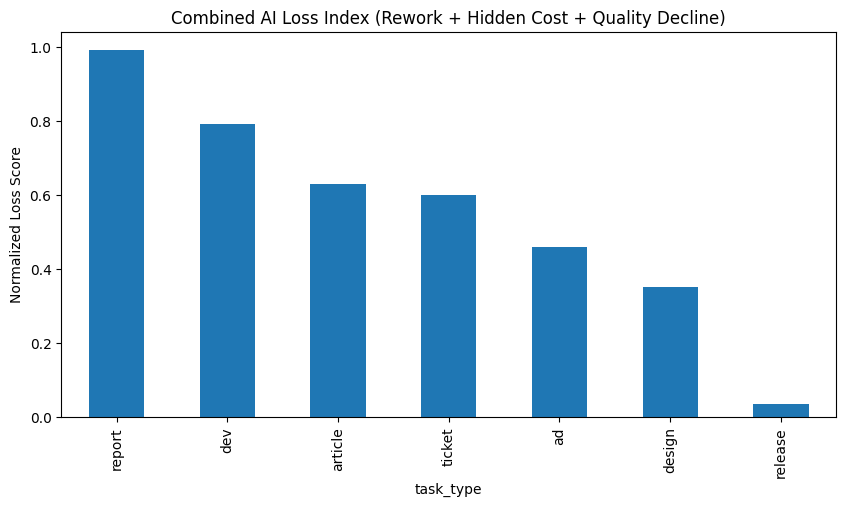

In [26]:
#normalize all loss metrics to a 0-1 scale so they carry equal weight
scaler = MinMaxScaler()
normalized_losses = pd.DataFrame(
    scaler.fit_transform(losses),
    index=losses.index,
    columns=loss_cols
)

#combined mean AI loss score
loss_df['AI_Loss_Index'] = normalized_losses.mean(axis=1)

loss_df['AI_Loss_Index'].sort_values(ascending=False).plot(kind='bar', figsize=(10,5))
plt.title('Combined AI Loss Index (Rework + Hidden Cost + Quality Decline)')
plt.ylabel('Normalized Loss Score')

Rework increases as AI usage goes up showing that higher AI use leads to more errors that need fixing.<br>
Extra hours are highest at medium AI usage and drop at high levels. This shows hidden costs are persistent at all ai usage levels.<br>
Quality stays roughly stable at low and medium AI usage but drops slightly at high levels. This suggests that a lot of AI use may start to hurt output quality.


ai_bin
Medium    1447
Low       1339
High       395
Name: count, dtype: int64
count    3181.000000
mean        0.362029
std         0.195363
min         0.000000
25%         0.210000
50%         0.350000
75%         0.500000
max         0.930000
Name: ai_usage_pct, dtype: float64


Text(0.5, 0, 'AI Usage Level')

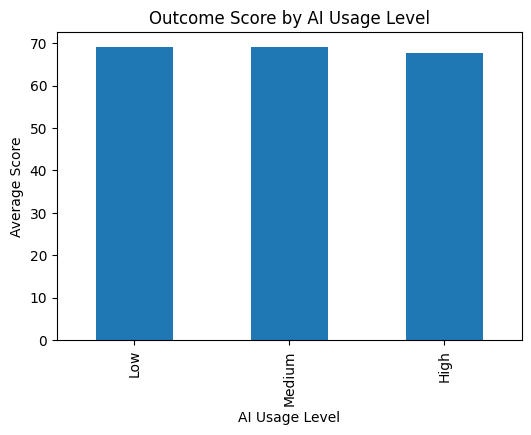

In [27]:
#creates bins to view levels of AI usage
df_clean['ai_bin'] = pd.cut(
    df_clean['ai_usage_pct'],
    bins=[0, 0.3, 0.6, 1],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

#checking num of observations
print(df_clean['ai_bin'].value_counts())
print(df_clean['ai_usage_pct'].describe())

#outcome score by AI usage level
df_clean.groupby('ai_bin')['outcome_score'].mean().plot(kind='bar', figsize=(6,4))
plt.title('Outcome Score by AI Usage Level')
plt.ylabel('Average Score')
plt.xlabel('AI Usage Level')

### 3. AI -> quality or just speed?

Distinguish the two effects in the data


In [28]:
#compare speed vs quality for AI and for non-AI
sq_metrics = ['hours_spent', 'outcome_score', 'rework_hours']
sq_df = df_clean.groupby('ai_assisted')[sq_metrics].mean()
print(sq_df)

#hours_spent is lower -> faster
#outcome_score is higher -> better quality
#rework_hours is lower -> less rework needed

             hours_spent  outcome_score  rework_hours
ai_assisted                                          
False          13.410804      69.011363      2.467806
True           12.994673      68.835313      2.426564


In [29]:

#calculating percent change for time, quality, and rework between AI-assisted and non-AI-assisted tasks
#how much did this change when we used AI instead of not using AI?
#change = (AI value - Non-AI value) / Non-AI value
sq_change = {
    'time_change': (sq_df.loc[True, 'hours_spent'] - sq_df.loc[False, 'hours_spent']) / sq_df.loc[False, 'hours_spent'],
    'quality_change': (sq_df.loc[True, 'outcome_score'] - sq_df.loc[False, 'outcome_score']) / sq_df.loc[False, 'outcome_score'],
    'rework_change': (sq_df.loc[True, 'rework_hours'] - sq_df.loc[False, 'rework_hours']) / sq_df.loc[False, 'rework_hours']
}

sq_change = pd.DataFrame(sq_change, index=['AI vs Non-AI'])

print(sq_change)
print(sq_df)


              time_change  quality_change  rework_change
AI vs Non-AI     -0.03103       -0.002551      -0.016712
             hours_spent  outcome_score  rework_hours
ai_assisted                                          
False          13.410804      69.011363      2.467806
True           12.994673      68.835313      2.426564


AI improves efficiency by reducing time and rework. However, this comes with a small drop in output quality.


(array([0, 1, 2]),
 [Text(0, 0, 'time_change'),
  Text(1, 0, 'quality_change'),
  Text(2, 0, 'rework_change')])

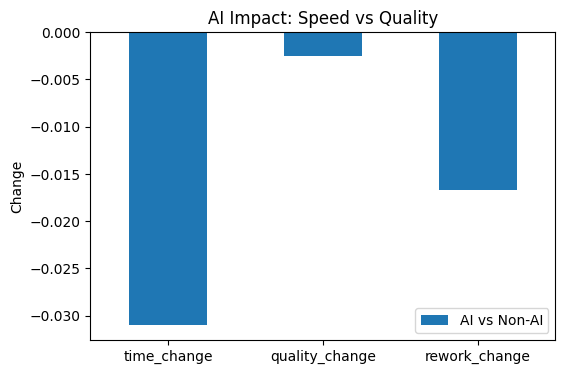

In [30]:
#plots the values
sq_change.T.plot(kind='bar', figsize=(6,4))
plt.title('AI Impact: Speed vs Quality')
plt.ylabel('Change')
plt.xticks(rotation=0)

#positive = higher with AI
#negative = lower with AI

#time_change negative -> AI is faster
#quality_change negative -> AI lowers quality
#rework_change negative -> AI reduces rework

### 4. When does it become negative?

Find the critical threshold beyond which AI harms the margin.


In [31]:
#group data by ai usage level and calculate mean profit, rework hours, and extra hours for each bin
threshold_df = df_clean.groupby('ai_bin')[['profit', 'rework_hours', 'extra_hours']].mean()
print(threshold_df)

            profit  rework_hours  extra_hours
ai_bin                                       
Low     249.969499      2.060306     4.672648
Medium  401.968450      2.610608     4.842920
High    489.082480      3.064607     3.615678


Higher AI usage yields more profit


Text(0.5, 0, 'AI Usage Level')

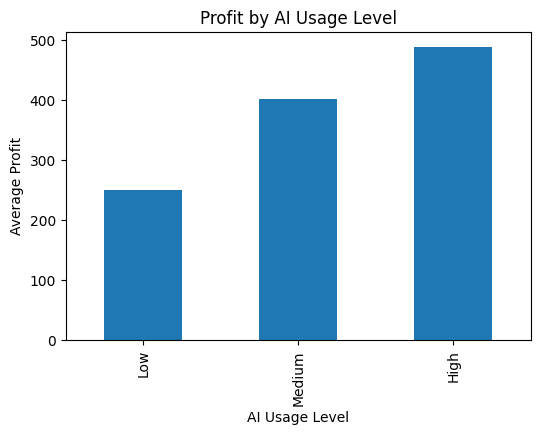

In [32]:
#plot profit by ai usage level
threshold_df['profit'].plot(kind='bar', figsize=(6,4))

plt.title('Profit by AI Usage Level')
plt.ylabel('Average Profit')
plt.xlabel('AI Usage Level')

Rework hours increase as AI usage increases meaning higher AI use leads to more errors. <br>
Using some AI can reduce rework (what we saw in question 2 comparing all AI tasks vs non-AI tasks), but relying on it too much actually increases errors.


Text(0.5, 0, 'AI Usage Level')

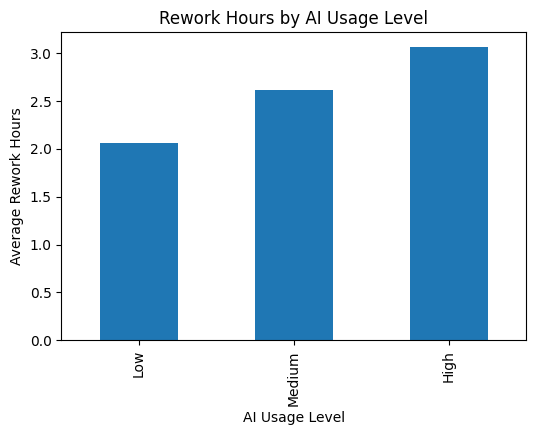

In [33]:
#plot rework hours by ai usage level  
threshold_df['rework_hours'].plot(kind='bar', figsize=(6,4))

plt.title('Rework Hours by AI Usage Level')
plt.ylabel('Average Rework Hours')
plt.xlabel('AI Usage Level')

Extra (non-billable) hours are highest at medium AI usage and decrease at high levels. Medium AI use may create more hidden costs than very high use.


Text(0.5, 0, 'AI Usage Level')

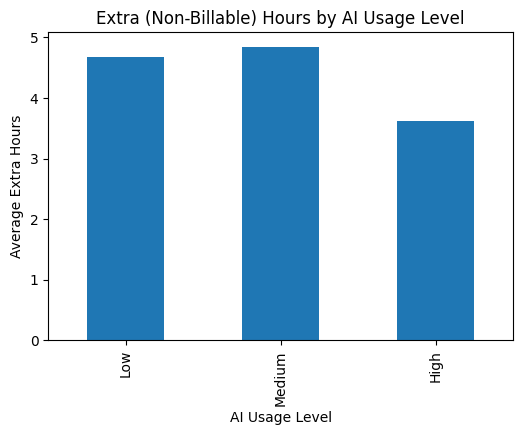

In [34]:
#plot extra hours by ai usage level (hidden cost)
threshold_df['extra_hours'].plot(kind='bar', figsize=(6,4))

plt.title('Extra (Non-Billable) Hours by AI Usage Level')
plt.ylabel('Average Extra Hours')
plt.xlabel('AI Usage Level')


More AI appears to, on average, generate more profit as is shown in the scatter graph, as well as the rolling average graph, which helps add visually distinguishable patterns and break points to the graph.

Text(0.5, 0, 'AI Usage')

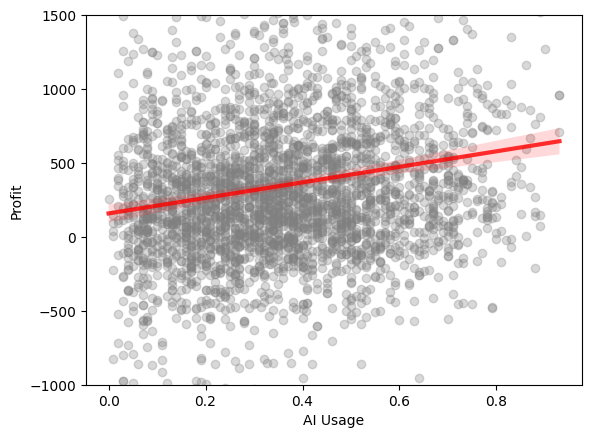

In [35]:
# scatter plot for proft vs AI usage percentage to see if there is a clear relationship 
# or threshold where profit starts to decline
ax = sns.scatterplot()
# we limit the scale of the y-axis to better see the trend
ax.set_ylim(-1000, 1500)

sns.regplot(df_clean, 
            x='ai_usage_pct', 
            y='profit', 
            scatter_kws={'color': 'gray', 'alpha': 0.3},
            line_kws={'color': 'red', 'alpha': 0.8, 'lw': 3})
plt.ylabel('Profit')
plt.xlabel('AI Usage')

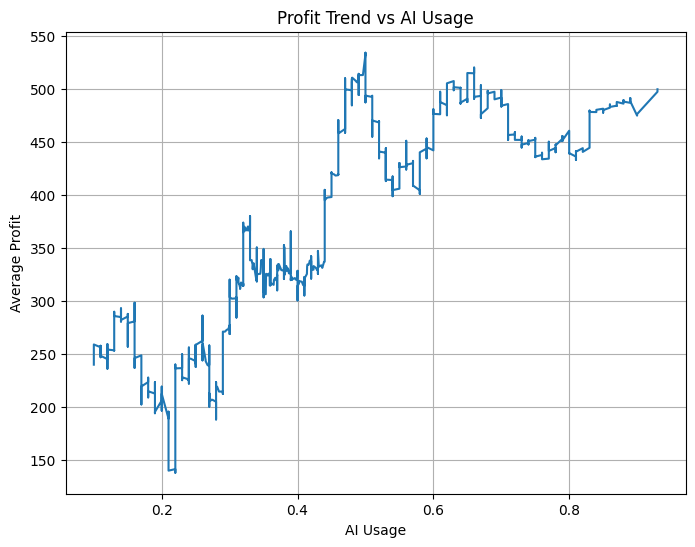

In [36]:
#sort data by AI usage so the trend line follows AI usage from low to high
df_sorted = df_clean.sort_values('ai_usage_pct')

rolling_profit = df_sorted['profit'].rolling(window=300).mean()

#plot the smoother profit trend
plt.figure(figsize=(8,6))
plt.plot(df_sorted['ai_usage_pct'], rolling_profit)

plt.xlabel('AI Usage')
plt.ylabel('Average Profit')
plt.title('Profit Trend vs AI Usage')
plt.grid(True)

In [37]:
#compare profit, rework, and hidden costs across AI usage levels
threshold_df = df_clean.groupby('ai_bin')[['profit', 'rework_hours', 'extra_hours']].mean()
print(threshold_df)

            profit  rework_hours  extra_hours
ai_bin                                       
Low     249.969499      2.060306     4.672648
Medium  401.968450      2.610608     4.842920
High    489.082480      3.064607     3.615678


The data suggests a threshold around 40-45% AI usage. Beyond which increased AI use typically causes more rework even though profit continues to rise.

In [38]:
df_clean['ai_usage_pct'].quantile([0.6, 0.7])

0.6    0.40
0.7    0.46
Name: ai_usage_pct, dtype: float64

We compare the standard deviation in profit by AI usage bins, to see whether AI makes the outputs more or less predictable. The bar graph reveals that higher AI usage actually makes the standard deviation in profit more predictable on average.

ai_bin
Low       916.997196
Medium    888.004009
High      778.071581
Name: profit, dtype: float64


Text(0.5, 0, 'AI Usage Level')

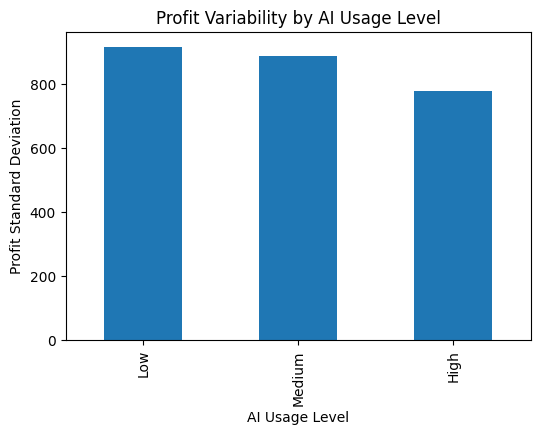

In [39]:
#check whether higher AI usage also makes profit more unstable
profit_risk = df_clean.groupby('ai_bin')['profit'].std()

print(profit_risk)

profit_risk.plot(kind='bar', figsize=(6,4))
plt.title('Profit Variability by AI Usage Level')
plt.ylabel('Profit Standard Deviation')
plt.xlabel('AI Usage Level')

### Pricing model analysis
We analyze the financial and operative performance metrics (revenue, cost, profit, hours spent, and revenue per hour) based on the pricing model and whether the task was AI-assisted or not. 

In terms of revenue, costs and profit, the value based model seems to perform most similarly whether using or not using AI. For the fixed and hourly priced models, using AI drives down both costs and revenue, which results in greater profits for AI assisted fixed model tasks, however lower profits for AI assisted hourly model tasks. Revenue per hour metrics highlight a unique risk for the hourly model – it is the only pricing structure where AI integration leads to a decrease in hourly earnings.

  pricing_model  ai_assisted      revenue        cost      profit  \
0         fixed        False  1161.080922  849.006677  312.074245   
1         fixed         True  1116.676280  749.152211  367.524069   
2        hourly        False  1195.001426  783.769310  411.232116   
3        hourly         True  1062.833542  772.127771  290.705771   
4   value_based        False  1219.650042  772.909457  446.740586   
5   value_based         True  1221.235299  779.181591  442.053709   

   hours_spent  rev_per_hour  
0    13.276545    156.375592  
1    12.827930    258.921849  
2    13.376161    287.987726  
3    13.189855    212.942947  
4    13.914781    104.001906  
5    12.767226    195.131099  


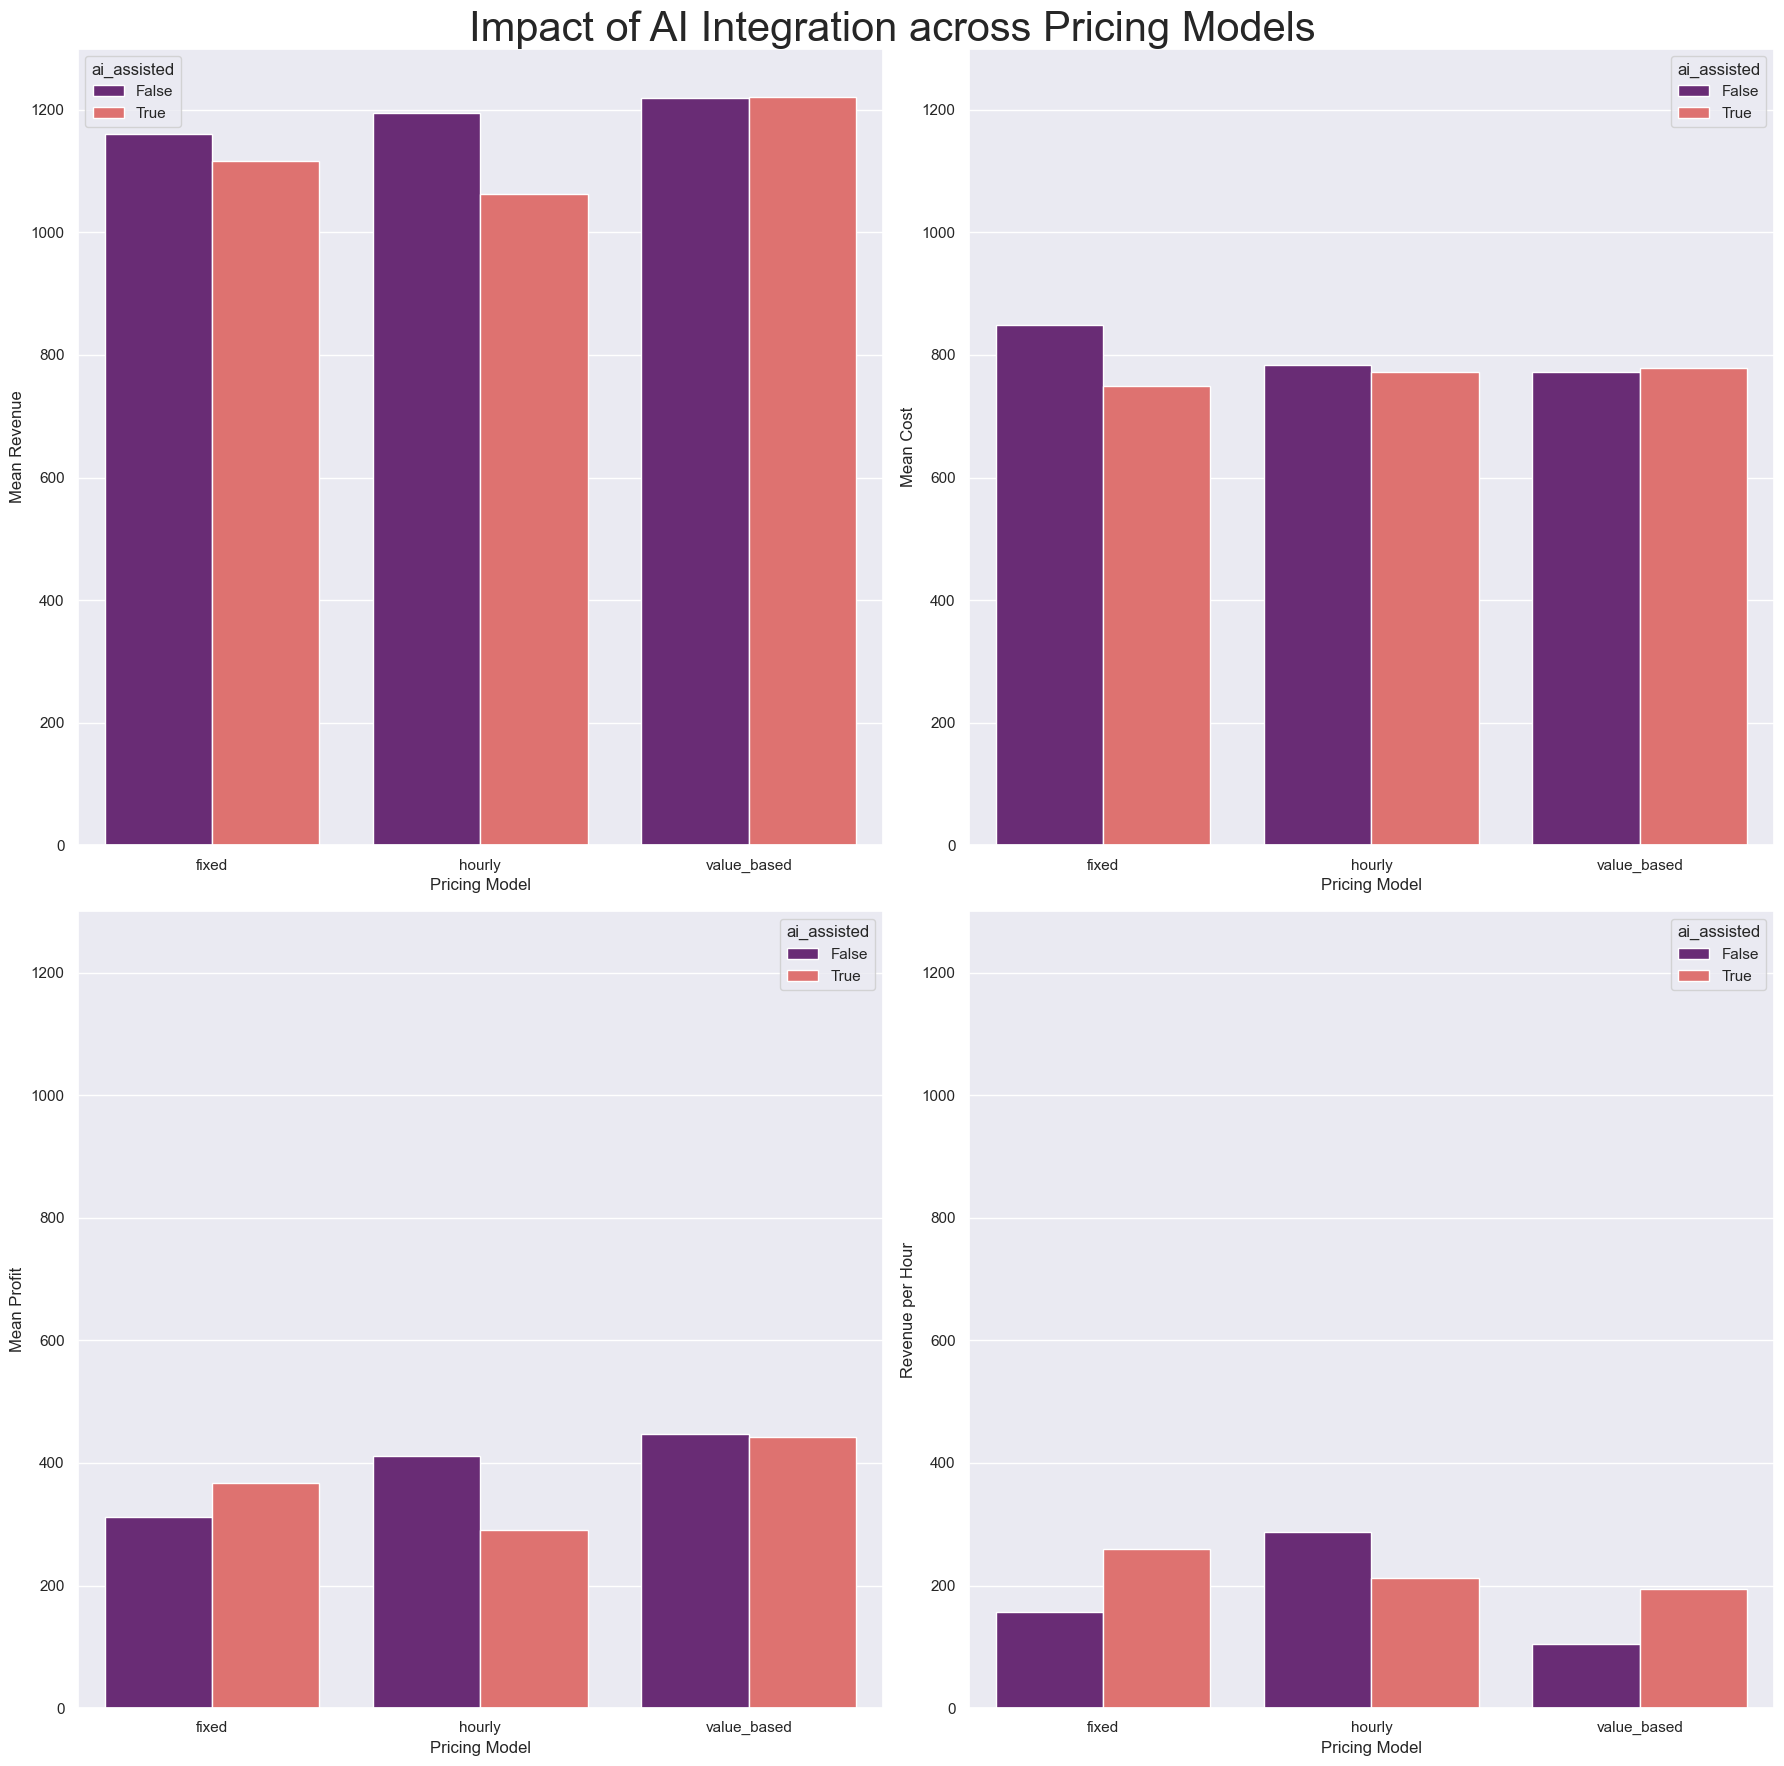

In [40]:
# Find revenue per hour spent
df_clean['rev_per_hour'] = df_clean['revenue'] / df_clean['hours_spent']

# Group by pricing model and AI assistance
pricing_impact = df_clean.groupby(['pricing_model', 'ai_assisted'])[['revenue', 'cost', 'profit', 'hours_spent', 'rev_per_hour']].mean().reset_index()

print(pricing_impact)

# Visualize
sns.set_theme(style="darkgrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 18))

sns.barplot(ax=axes[0][0], data=pricing_impact, x='pricing_model', y='revenue', hue='ai_assisted', palette='magma')
axes[0][0].set_ylabel('Mean Revenue')
axes[0][0].set_xlabel('Pricing Model')
axes[0][0].set_ylim(0, 1300)

sns.barplot(ax=axes[0][1], data=pricing_impact, x='pricing_model', y='cost', hue='ai_assisted', palette='magma')
axes[0][1].set_ylabel('Mean Cost')
axes[0][1].set_xlabel('Pricing Model')
axes[0][1].set_ylim(0, 1300)

sns.barplot(ax=axes[1][0], data=pricing_impact, x='pricing_model', y='profit', hue='ai_assisted', palette='magma')
axes[1][0].set_ylabel('Mean Profit')
axes[1][0].set_xlabel('Pricing Model')
axes[1][0].set_ylim(0, 1300)

sns.barplot(ax=axes[1][1], data=pricing_impact, x='pricing_model', y='rev_per_hour', hue='ai_assisted', palette='magma')
axes[1][1].set_ylabel('Revenue per Hour')
axes[1][1].set_xlabel('Pricing Model')
axes[1][1].set_ylim(0, 1300)

plt.suptitle('Impact of AI Integration across Pricing Models', fontsize=30)
plt.tight_layout()

## Impact of AI Usage on Features by Task Complexity
### Profit
High AI Usage is associated with greater profits for all tasks complexity levels save for the simplest tasks (complexity 1.0), where Mid or Low usage outperform.

Text(117.24999999999999, 0.5, 'Task Complexity')

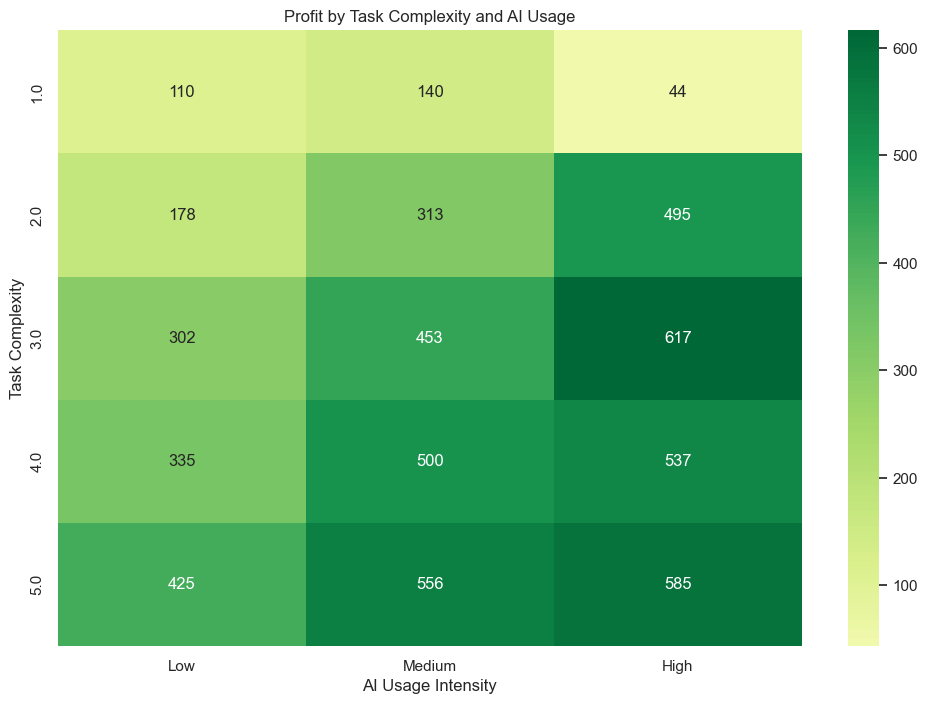

In [41]:
# Profit by Task Complexity and AI Usage Heatmap

# Pivot data to show mean profit by AI usage bin and task complexity
profit_matrix = df_clean.pivot_table(
    index='task_complexity_score', 
    columns='ai_bin', 
    values='profit', 
    aggfunc='mean'
)

# Plot
plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".0f", cmap='RdYlGn', center=0)
plt.title('Profit by Task Complexity and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Complexity')

### Hours Spent
High AI usage is associated with fewer hours spent for all complexity levels.

Text(117.24999999999999, 0.5, 'Task Complexity')

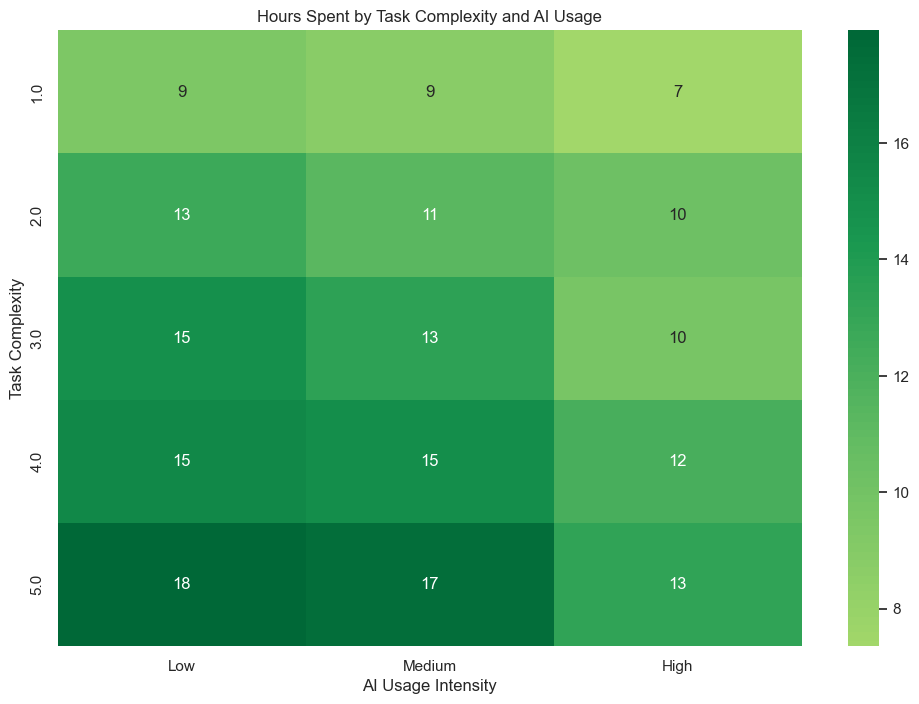

In [42]:
# Hours Spent by Task Complexity and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_complexity_score', 
    columns='ai_bin', 
    values='hours_spent', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".0f", cmap='RdYlGn', center=0)
plt.title('Hours Spent by Task Complexity and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Complexity')

### Rework Hours
High AI usage is associated with more rework hours across all complexity levels.

Text(117.24999999999999, 0.5, 'Task Complexity')

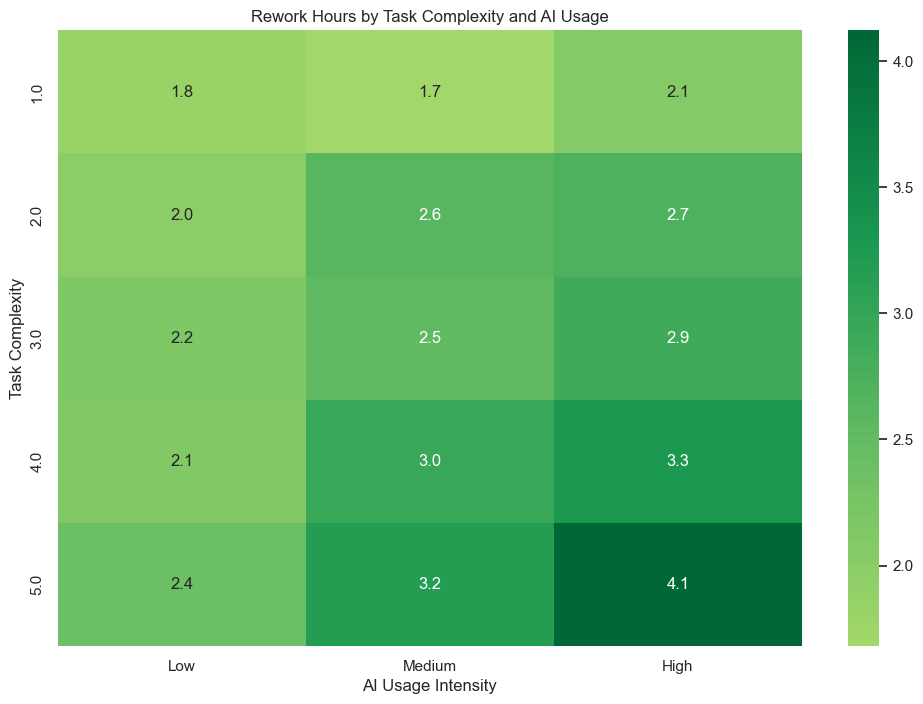

In [43]:
# Rework Hours by Task Complexity and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_complexity_score', 
    columns='ai_bin', 
    values='rework_hours', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".1f", cmap='RdYlGn', center=0)
plt.title('Rework Hours by Task Complexity and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Complexity')

### Errors
High AI usage is associated with more erros across levels 1.0 through 3.0. At complexity of 4.0 all AI usage intensities are more-or-less equal, while at complexity 5.0 high AI usage has the fewest errors.

Text(117.24999999999999, 0.5, 'Task Complexity')

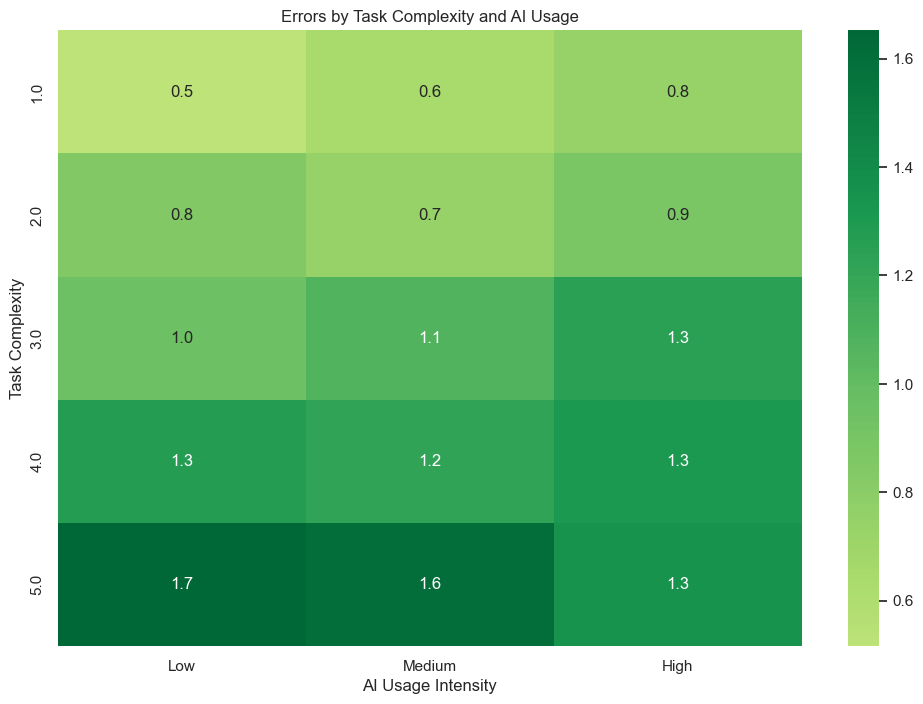

In [44]:
# Errors by Task Complexity and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_complexity_score', 
    columns='ai_bin', 
    values='errors', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".1f", cmap='RdYlGn', center=0)
plt.title('Errors by Task Complexity and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Complexity')

### Outcome Score
Highest outcome scores are associated with mid AI usage for all but the simplest tasks (complexity 1.0), where low and high AI usage achieves better results. At the highest complexity level, low AI usage also slightly outperforms mid usage.

Text(117.24999999999999, 0.5, 'Task Complexity')

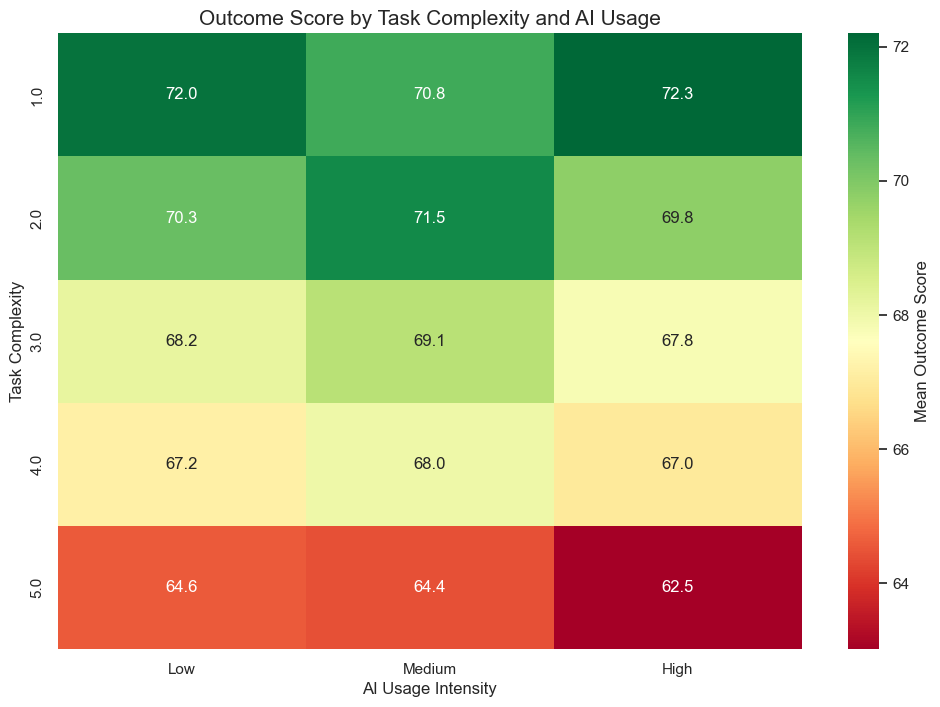

In [45]:
# Outcome Score by Task Complexity and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_complexity_score', 
    columns='ai_bin', 
    values='outcome_score', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))

# more colorfully-distinct heatmap to better distinguish between the values
sns.heatmap(
    profit_matrix, 
    annot=True, 
    fmt=".1f", 
    cmap='RdYlGn',
    robust=True,
    cbar_kws={'label': 'Mean Outcome Score'}
)

plt.title('Outcome Score by Task Complexity and AI Usage', fontsize=15)
plt.xlabel('AI Usage Intensity', fontsize=12)
plt.ylabel('Task Complexity', fontsize=12)

## Impact of AI Usage on Features by Task Type
### Profit
High AI usage achieves greatest profits for release, report and dev tasks. Mid AI usage performs best at ad, article and design tasks. Low AI usage is never best.

Text(117.24999999999999, 0.5, 'Task Type')

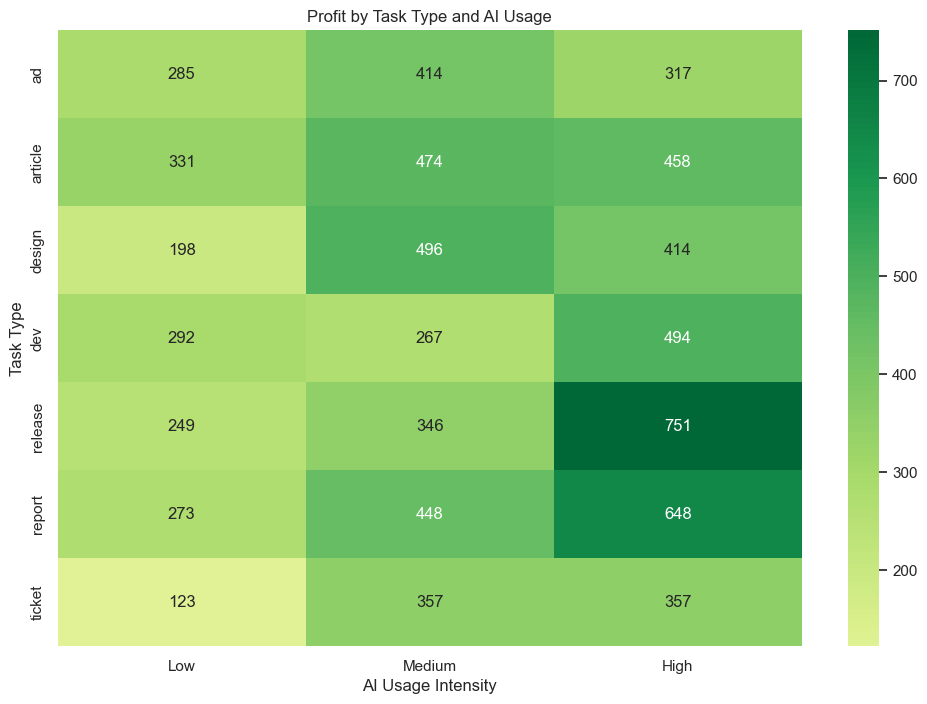

In [46]:
# Profit by Task Type and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_type', 
    columns='ai_bin', 
    values='profit', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".0f", cmap='RdYlGn', center=0)
plt.title('Profit by Task Type and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Type')

### Hours Spent
High AI usage is associated with fewest hours spent across all task types, especially for dev, release and report tasks.

Text(117.24999999999999, 0.5, 'Task Type')

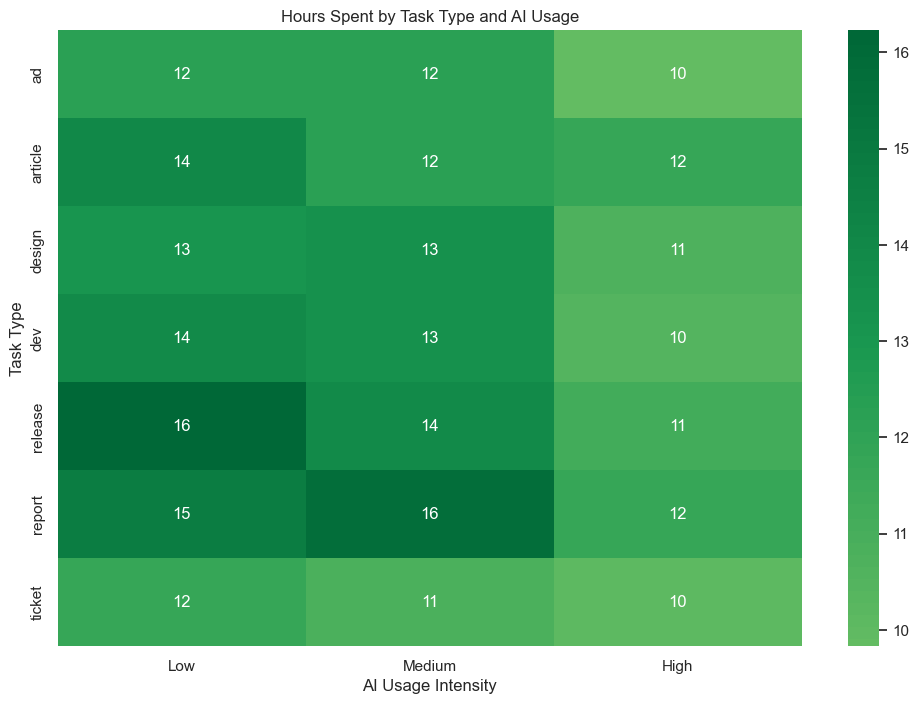

In [47]:
# Hours Spent by Task Type and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_type', 
    columns='ai_bin', 
    values='hours_spent', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".0f", cmap='RdYlGn', center=0)
plt.title('Hours Spent by Task Type and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Type')

### Rework Hours
High AI usage is associated with most rework hours across all task types, especially dev, design and report tasks.

Text(117.24999999999999, 0.5, 'Task Type')

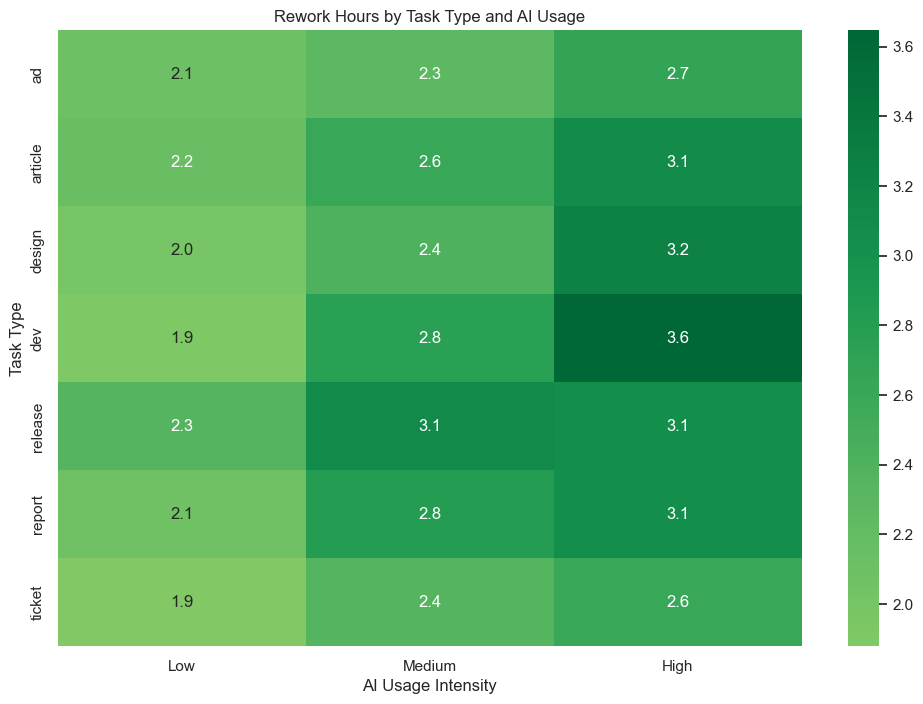

In [48]:
# Rework Hours by Task Type and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_type', 
    columns='ai_bin', 
    values='rework_hours', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".1f", cmap='RdYlGn', center=0)
plt.title('Rework Hours by Task Type and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Type')

### Errors
High AI usage is associated with most errors across all task types (save for dev tasks), especially release, report and ticket tasks.

Text(117.24999999999999, 0.5, 'Task Type')

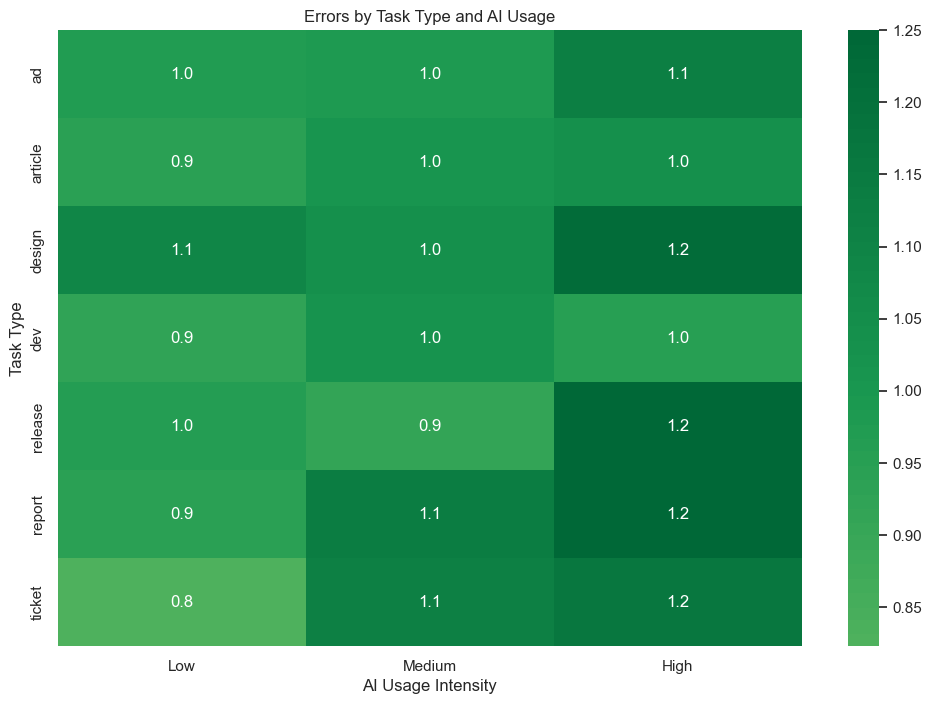

In [49]:
# Errors by Task Type and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_type', 
    columns='ai_bin', 
    values='errors', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(profit_matrix, annot=True, fmt=".1f", cmap='RdYlGn', center=0)
plt.title('Errors by Task Type and AI Usage')
plt.xlabel('AI Usage Intensity')
plt.ylabel('Task Type')

### Outcome Score
High AI usage is generally associated with lowest outcome scores across all task types (especially poorly in articles and report tasks), except for design tasks where it performs best. Generally, low or mid AI usage performs best with similar scores across the board, except for ticket tasks where low AI usage outperforms.

Text(117.24999999999999, 0.5, 'Task Type')

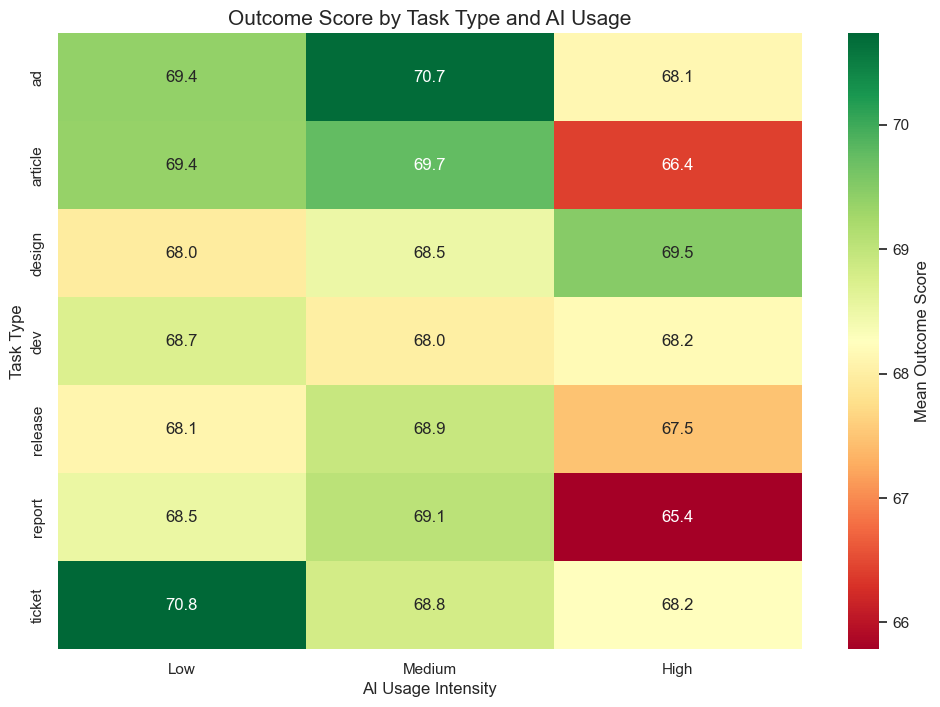

In [50]:
# Outcome Score by Task Type and AI Usage Heatmap
profit_matrix = df_clean.pivot_table(
    index='task_type', 
    columns='ai_bin', 
    values='outcome_score', 
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(
    profit_matrix, 
    annot=True, 
    fmt=".1f", 
    cmap='RdYlGn',
    robust=True,
    cbar_kws={'label': 'Mean Outcome Score'}
)
plt.title('Outcome Score by Task Type and AI Usage', fontsize=15)
plt.xlabel('AI Usage Intensity', fontsize=12)
plt.ylabel('Task Type')

# Conclusion
* Gradient boosting with SHAP analysis shows AI usage strongly affects profit, outcomes, error rates, and time spent, making it a key performance driver across tasks.

* Value analysis indicates the greatest gains in profit, outcomes, and efficiency come from release and design work, where AI contributes the most added value.

* Loss analysis finds the highest inefficiencies (measured by rework, extra hours, and weaker outcomes) are concentrated in report writing and development tasks.

* Increased AI usage reduces total and extra hours while boosting profit, but also leads to more rework, lower quality, and higher variability in outcomes.

* Pricing analysis shows value-based models remain stable with or without AI, while fixed and hourly models see reduced costs and revenue which improves profits in fixed pricing but harms profitability in hourly work.  Fixed and value-based approaches are favored, with a focus on cost control in value pricing, while the hourly model should be phased out due to declining returns under AI use.

* Task complexity analysis highlights a consistent trade-off: high AI use improves speed and profitability but increases errors and rework, especially in complex tasks where moderate or low AI use often yields better quality.

**Strategic recommendations:**

* Kill hourly pricing – it punishes efficiency and is the only model where AI lowers earnings. Shift to fixed and value-based.

* Control AI usage, don’t maximize it – use high AI for structured work, but limit it in creative/simple tasks and require review to cut rework.

* Build QA into the process – assume AI outputs need correction and add checkpoints instead of treating errors as exceptions.

* Double down where AI works – prioritize release and design tasks. Tighten controls on reports and development where losses are highest.

* Track rework as a core metric – profit alone is misleading – rising rework will quietly erase gains if you don’t monitor it.
